# 06 · What is the faintest Hα and [O III] line flux the IFS can detect at z ≈ 1 in an hour?

At $z \approx 1$, near the peak of cosmic star formation, Hα lands at 1.31 µm and [O III] 5007 at 1.00 µm: both in the near-infrared where ground-based work fights OH sky lines. A space IFS sees a dark, smooth background (zodiacal light) instead, so the line-flux sensitivity is set by detector noise and zodi. Here we inject a Gaussian emission line on a faint continuum and find the 5σ line-flux limit in one hour, then map it across redshift.

**Instrument / code:** Lazuli IFS, `slicersim` (v1.3.4): `LazuliTarget` with a custom spectrum, `change_detector`, `get_spectrum`, `get_resolving_power`.

## Prompt to try in Jupyter AI

> Using `slicersim` (Lazuli IFS simulator), build a custom spectrum on a 1 Å grid from 3000 to 20000 Å: a flat-in-f_nu continuum at 25 AB mag plus a Gaussian emission line (intrinsic sigma 100 km/s) at Hα 6563 Å × (1+z) for z = 1, with a total line flux F in erg/s/cm².
> Average the input spectrum over the IFS wavelength bins first (slicersim interpolates the input at bin centres, so a narrow line would be missed), then wrap it in `slicersim.LazuliTarget(lbda, flux)` (flux in erg/s/cm²/Å, mag=None), set a one-hour read-out with `change_detector(nmd=(53, 8, 0), nramps=3)`, and get `get_spectrum(unit="flambda", incl_error=False)`.
> Measure the line S/N by summing (spectrum − continuum-only spectrum) × dλ over ±1 FWHM of the line spread function (use `simulation.get_resolving_power()`), with the noise from the summed variance.
> Scan F to find the 5σ limit; repeat for [O III] 5007, then map the limit vs redshift for both lines.
> Plot S/N vs line flux at z = 1 and the 5σ limit vs redshift. State whether the target is treated as a point source, what the spectral resolution is at the line, and whether nearby lines ([N II], [O III] 4959) would be blended.

## Setup

One gotcha found while building this: slicersim evaluates a custom input spectrum by interpolating it at the IFS bin centres, so an unresolved line must be **bin-averaged first** (done in `model_spectrum` below) or it silently disappears.

`LazuliTarget` is a **point source** in slicersim (there is no extended-source mode for custom spectra), so this is the limit for a compact, unresolved galaxy. Continuum: flat in $f_\nu$ at 25 AB; line: Gaussian with intrinsic $\sigma_v = 100$ km/s (unresolved, the instrumental line spread function dominates).

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
# plt.style.use('gks')
import slicersim

print('slicersim', slicersim.__version__)
THUMB = Path('thumbs/06_emission_line_galaxies.png')
ONE_HOUR = dict(nmd=(53, 8, 0), nramps=3)
C_KMS, C_AS = 2.998e5, 2.998e18
LINES = {'Hα 6563': 6562.8, '[O III] 5007': 5006.8}
LAM = np.arange(3000, 20000, 1.0)
CONT_AB = 25.0
continuum = 3631e-23 * 10**(-0.4 * CONT_AB) * C_AS / LAM**2          # erg/s/cm2/A

# slicersim samples the input spectrum at the centre of each IFS wavelength bin (np.interp), then applies
# the LSF. A line narrower than a bin (~45 A here) would be missed, so we first average the input over the
# IFS bins: flux is conserved and the LSF is then applied by slicersim as usual.
LB = slicersim.LazuliTarget(LAM, continuum).simulation.spectrograph.lbda
EDGES = np.r_[LB[0] - (LB[1] - LB[0]) / 2, (LB[1:] + LB[:-1]) / 2, LB[-1] + (LB[-1] - LB[-2]) / 2]
IDX = np.searchsorted(EDGES, LAM)                 # bin index of each fine-grid sample

def bin_average(flux):
    mean = np.bincount(IDX, flux, minlength=len(EDGES) + 1) / np.maximum(np.bincount(IDX, minlength=len(EDGES) + 1), 1)
    return mean[IDX]

def model_spectrum(line_flux, lam_obs, sigma_kms=100.):
    sig = lam_obs * sigma_kms / C_KMS
    line = line_flux * np.exp(-0.5 * ((LAM - lam_obs) / sig)**2) / (np.sqrt(2 * np.pi) * sig)
    return bin_average(continuum + line)

def observe(flux):
    t = slicersim.LazuliTarget(LAM, flux)        # mag=None -> flux taken in erg/s/cm2/A
    t.change_detector(**ONE_HOUR)
    return t, t.get_spectrum(unit='flambda', incl_error=False)

cont_target, (lb, f_cont, v_cont) = observe(bin_average(continuum))
print(f"exposure: {cont_target.get_exposure_time():.0f} s")
lr, R = cont_target.simulation.get_resolving_power()
dl = np.gradient(lb)
for name, l0 in LINES.items():
    lo = l0 * 2
    print(f"{name} at z=1 -> {lo:.0f} A: R = {np.interp(lo, lr, R):.0f}, LSF FWHM = {lo/np.interp(lo, lr, R):.0f} A, pixel = {np.interp(lo, lb, dl):.0f} A")

slicersim 1.3.4


exposure: 3600 s
Hα 6563 at z=1 -> 13126 A: R = 116, LSF FWHM = 113 A, pixel = 49 A
[O III] 5007 at z=1 -> 10014 A: R = 101, LSF FWHM = 99 A, pixel = 43 A


## Line S/N

Signal = (line + continuum) − (continuum only), summed over ±1 LSF FWHM (times the pixel width $d\lambda$, so it is a line flux). Noise = $\sqrt{\sum \sigma^2 d\lambda^2}$ from the variance of the spectrum *with* the line, so the line's own photon noise is included. The noise-free (`incl_error=False`) spectrum gives the expected S/N.

In [2]:
def line_snr(line_flux, lam_obs):
    _, (_, f, v) = observe(model_spectrum(line_flux, lam_obs))
    fwhm = lam_obs / np.interp(lam_obs, lr, R)
    w = np.abs(lb - lam_obs) <= fwhm
    sig = np.sum((f - f_cont)[w] * dl[w])
    noise = np.sqrt(np.sum(v[w] * dl[w]**2))
    return sig / noise, sig

# sanity: recovered flux in the window vs injected (LSF wings outside +-1 FWHM are lost)
s, rec = line_snr(1e-16, LINES['Hα 6563'] * 2)
print(f"injected 1e-16, recovered {rec:.2e} in the window ({rec/1e-16:.0%}), S/N = {s:.0f}")

injected 1e-16, recovered 9.04e-17 in the window (90%), S/N = 51


## 5σ limit at z = 1: scan the line flux

In [3]:
FLUX = np.geomspace(1e-18, 3e-16, 14)
snr_z1, lim_z1 = {}, {}
for name, l0 in LINES.items():
    snr_z1[name] = np.array([line_snr(F, l0 * 2)[0] for F in FLUX])
    lim_z1[name] = 10**np.interp(np.log10(5), np.log10(snr_z1[name]), np.log10(FLUX))
    print(f"{name:13s} at z = 1: 5-sigma limit in 1 h = {lim_z1[name]:.2e} erg/s/cm2")

Hα 6563       at z = 1: 5-sigma limit in 1 h = 6.67e-18 erg/s/cm2


[O III] 5007  at z = 1: 5-sigma limit in 1 h = 8.07e-18 erg/s/cm2


## Limit versus redshift

The detector noise does not depend on the line, and the line's own photon noise adds variance linearly in its flux. So one noise-free injection per redshift (at $F_0 = 10^{-16}$) gives everything: the recovered signal per unit flux `eff` and the extra variance per unit flux `k`, from which $\mathrm{eff}\,F = 5\sqrt{N_0^2 + kF}$ is solved for $F$. We check this against the full flux scan at z = 1.

In [4]:
F0 = 1e-16

def limit_5sig(lam_obs):
    _, (_, f1, v1) = observe(model_spectrum(F0, lam_obs))
    w = np.abs(lb - lam_obs) <= lam_obs / np.interp(lam_obs, lr, R)
    n0sq = np.sum(v_cont[w] * dl[w]**2)
    eff = np.sum((f1 - f_cont)[w] * dl[w]) / F0
    k = (np.sum(v1[w] * dl[w]**2) - n0sq) / F0
    a, b, c = eff**2, -25 * k, -25 * n0sq        # quadratic in F
    return (-b + np.sqrt(b**2 - 4 * a * c)) / (2 * a)

for name, l0 in LINES.items():
    print(f"{name:13s}: per-z solve {limit_5sig(l0*2):.2e} vs full scan {lim_z1[name]:.2e} erg/s/cm2")

ZGRID = {n: np.arange(0.0, 2.5, 0.05) for n in LINES}
ZGRID = {n: z[(LINES[n] * (1 + z) > lb.min() + 300) & (LINES[n] * (1 + z) < lb.max() - 300)] for n, z in ZGRID.items()}
LIM = {n: np.array([limit_5sig(LINES[n] * (1 + z)) for z in ZGRID[n]]) for n in LINES}
for n in LINES:
    i = np.argmin(LIM[n])
    print(f"{n:13s}: z = {ZGRID[n].min():.2f}-{ZGRID[n].max():.2f}, limit {LIM[n].min():.1e} (best, z={ZGRID[n][i]:.2f}) to {LIM[n].max():.1e} (worst, z={ZGRID[n][np.argmax(LIM[n])]:.2f})")

Hα 6563      : per-z solve 6.65e-18 vs full scan 6.67e-18 erg/s/cm2


[O III] 5007 : per-z solve 8.04e-18 vs full scan 8.07e-18 erg/s/cm2


Hα 6563      : z = 0.00-1.50, limit 6.0e-18 (best, z=1.45) to 1.7e-17 (worst, z=0.00)
[O III] 5007 : z = 0.00-2.30, limit 5.9e-18 (best, z=2.20) to 2.2e-17 (worst, z=0.00)


## Hero figure

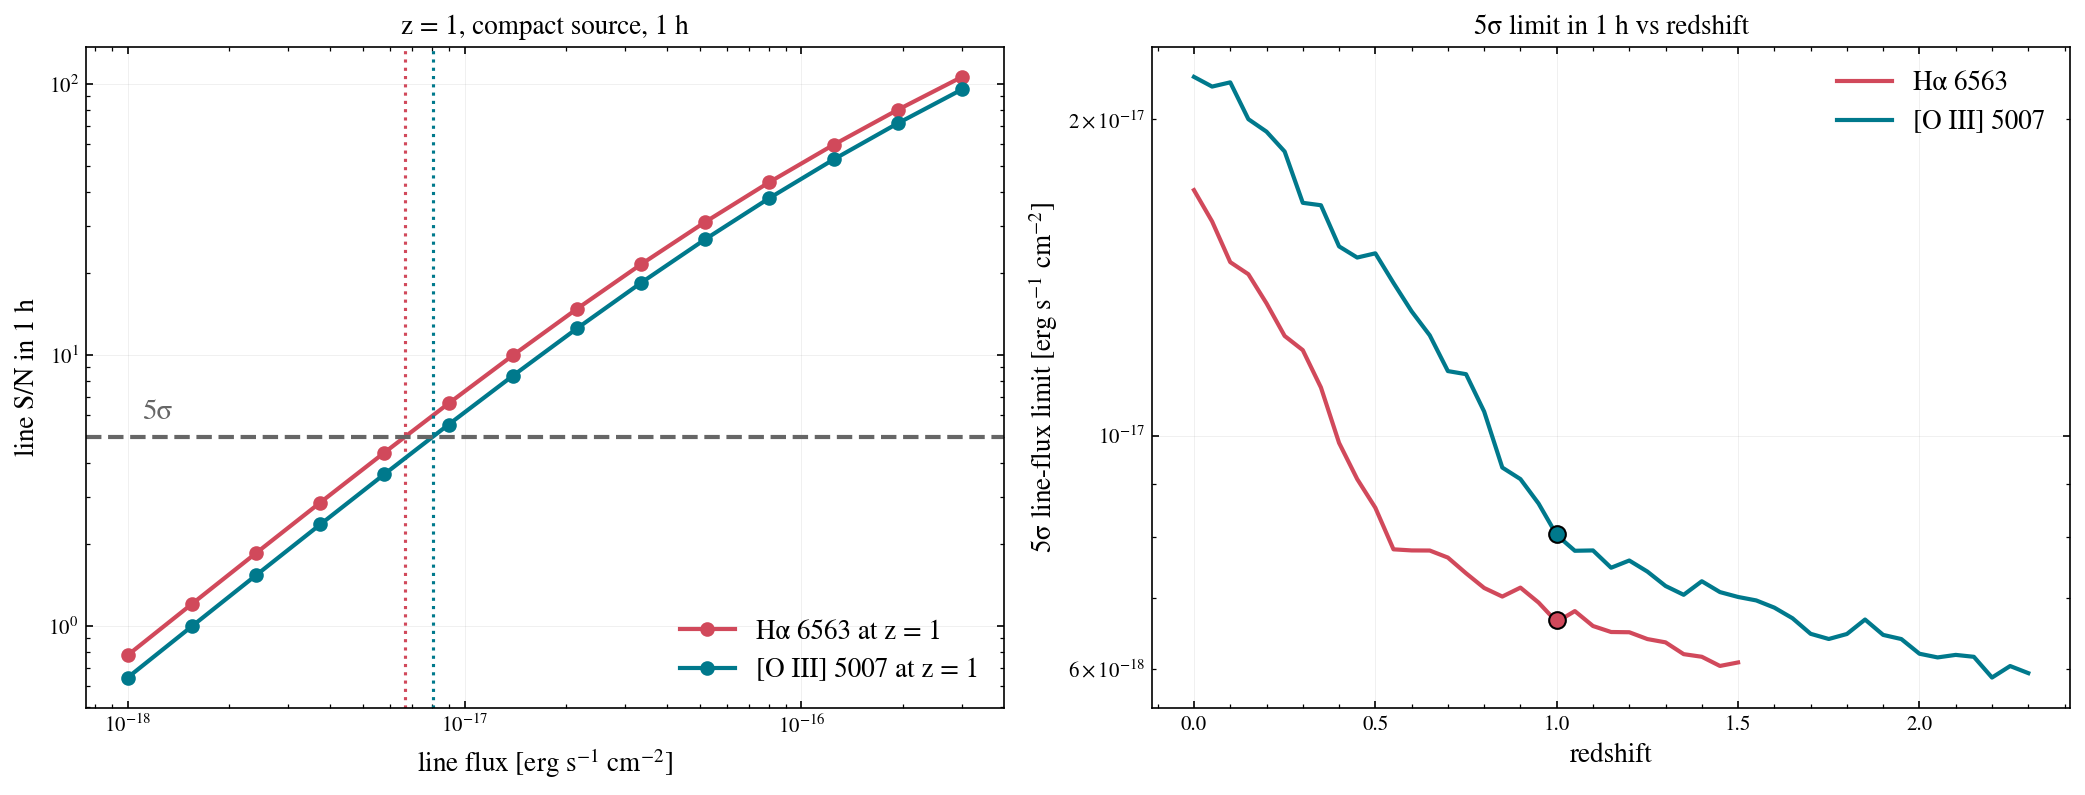

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4))
cols = {'Hα 6563': '#d1495b', '[O III] 5007': '#00798c'}
for n in LINES:
    ax1.loglog(FLUX, snr_z1[n], 'o-', color=cols[n], label=f'{n} at z = 1')
    ax1.axvline(lim_z1[n], color=cols[n], ls=':', lw=1.5)
ax1.axhline(5, color='0.4', ls='--')
ax1.text(1.1e-18, 5.8, '5σ', color='0.4', fontsize=14)
ax1.set(xlabel=r'line flux [erg s$^{-1}$ cm$^{-2}$]', ylabel='line S/N in 1 h', title='z = 1, compact source, 1 h')
ax1.legend(loc='lower right', fontsize=13)

for n in LINES:
    ax2.semilogy(ZGRID[n], LIM[n], color=cols[n], label=n)
    ax2.plot(1, lim_z1[n], 'o', color=cols[n], ms=8, mec='k')
ax2.set(xlabel='redshift', ylabel=r'5σ line-flux limit [erg s$^{-1}$ cm$^{-2}$]', title='5σ limit in 1 h vs redshift')
ax2.legend(fontsize=13)
fig.tight_layout()
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

For a compact source at z = 1, the 1-hour 5σ line-flux limit is **≈ 6.7 × 10⁻¹⁸ erg s⁻¹ cm⁻² for Hα** (at 1.31 µm) and **≈ 8.1 × 10⁻¹⁸ for [O III] 5007** (at 1.00 µm), on a 25 AB continuum. Across redshift the limit runs from ~2 × 10⁻¹⁷ (lines in the blue, z ≈ 0) down to ~6 × 10⁻¹⁸ (lines near 1.4–1.6 µm), so it improves towards the red end of the band.

## Caveats & next steps

- **Point source only:** `LazuliTarget` places the spectrum in the PSF; a real $z \sim 1$ star-forming galaxy is extended (0.3–1″), which spreads the line over more spaxels and raises the noise. Treat these limits as optimistic for compact sources.
- **Low resolution:** at $R \approx 100$–150 in the NIR, Hα is fully blended with [N II] 6548/6583 and [O III] 5007 partly with 4959, so the "line flux" here is really a blend; there is no kinematics at this resolution.
- **Simple detection metric:** a box sum over ±1 FWHM (which loses the LSF wings) rather than an optimally-weighted Gaussian fit; a matched filter would gain roughly 10–20%. The redshift map uses an analytic shortcut calibrated at z = 1 (checked against the full scan above); the limit also depends on the assumed continuum (25 AB) and zodiacal background level.
- **Ideas:** (1) add [N II] and Hβ to the template and ask whether Hα/[N II] can be deblended at all; (2) use `cont_target.get_variance_contribution()` to see whether zodi, dark or read noise sets the floor at 1.3 µm, and how the limit scales with exposure time; (3) replace the box sum with a fit of the LSF-convolved line profile.